# CornSight — Notebook 1: Training the Satellite Model
**Team:** Akane Eto, Alonso Manchego, Divisha Chellani, Nil Gaziyeva, Tsai-Ling Chen
**Professor:** Kurnicki — Hult International Business School
**Project:** CornSight — using satellite imagery and an AI agent to get an early read on the US corn harvest

In this notebook we fine-tune **Prithvi-EO-2.0**, NASA and IBM's satellite foundation model on Hugging Face, so it can tell corn apart from other crops in satellite photos of US farmland.

Our first test run used about 600 images and 5 epochs. For this final run we scaled up:
- We used the **full training set** (3,083 image chips), about four times more data.
- We trained for **12 epochs** with a learning rate that tapers off gradually, which helps the model settle.
- We **save progress to Google Drive** after every epoch, because Colab sessions can disconnect during a long run.
- At the end we **score every test image** and save a results table (`chip_results.csv`) with each chip's location, photo dates, predicted vs. actual corn share, and corn health (NDVI). Notebook 2 picks up from this table.

**To run:** set `Runtime > Change runtime type > T4 GPU`, then run the cells top to bottom. The full run took us about an hour (about 5 minutes to download and unzip the data, 44.5 minutes to train).

## Step 1 — Install the toolkit
Colab sometimes asks to restart the session after this install. If it does, restart, skip this cell and carry on from Step 2.

In [7]:
!pip install -q terratorch==1.2.14

## Step 2 — Connect Google Drive and load libraries
We save the model checkpoints and results to `MyDrive/cornsight/` so a disconnect doesn't wipe out the training run.

In [8]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/cornsight"
except ImportError:            # running outside Colab
    SAVE_DIR = "./cornsight_results"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import os, glob, shutil, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import albumentations as A
from albumentations.pytorch import ToTensorV2
import lightning.pytorch as pl
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

from terratorch.datamodules import MultiTemporalCropClassificationDataModule
from terratorch.tasks import SemanticSegmentationTask
from terratorch.datasets.transforms import FlattenTemporalIntoChannels, UnflattenTemporalFromChannels

HAS_GPU = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "NONE — go to Runtime > Change runtime type > T4 GPU")

GPU: Tesla T4


## Step 3 — Settings

In [10]:
DATA_ROOT = "/content/crop_data" if os.path.exists("/content") else "./crop_data"  # keep the images on Colab's local disk (much faster than Drive)
os.makedirs(SAVE_DIR, exist_ok=True)

# Model size
# We went with the tiny version so training fits on a free T4; the 100M version is more accurate but much slower
BACKBONE = "prithvi_eo_v2_tiny_tl"

EPOCHS      = 12     # 44.5 min on a free T4 GPU in our final run
BATCH_SIZE  = 16
LR          = 2.0e-4
NUM_WORKERS = 2      # Colab gives us 2 CPU cores
SEED        = 0

BANDS = ["BLUE", "GREEN", "RED", "NIR_NARROW", "SWIR_1", "SWIR_2"]
NUM_FRAMES = 3

CLASS_NAMES = ["Natural_Vegetation", "Forest", "Corn", "Soybeans", "Wetlands", "Developed_Barren",
               "Open_Water", "Winter_Wheat", "Alfalfa", "Fallow_Idle_Cropland", "Cotton", "Sorghum", "Other"]
CORN = CLASS_NAMES.index("Corn")
CLASS_WEIGHTS = [0.386375, 0.661126, 0.548184, 0.640482, 0.876862, 0.925186, 3.249462,
                 1.542289, 2.175141, 2.272419, 3.062762, 3.626097, 1.198702]

## Step 4 — Download the dataset (~11.8 GB)
- **Training set:** 3,083 chips. The model learns from these.
- **Validation set:** 771 chips. We test on these, so they're places the model has never seen.

Each chip is a 224 × 224-pixel square, about 6.7 km across, somewhere in the US. Each was photographed three times during the 2022 growing season, and every pixel is labelled with the crop growing there.

In [11]:
from huggingface_hub import hf_hub_download

REPO = "ibm-nasa-geospatial/multi-temporal-crop-classification"
os.makedirs(DATA_ROOT, exist_ok=True)

def fetch_and_extract(archive):
    folder = os.path.join(DATA_ROOT, archive.replace(".tgz", ""))
    if os.path.isdir(folder) and len(os.listdir(folder)) > 0:
        print(f"{folder} already there, skipping")
        return
    t0 = time.time()
    path = hf_hub_download(REPO, archive, repo_type="dataset", local_dir=DATA_ROOT)
    print(f"Downloaded {archive} in {time.time()-t0:.0f}s, unzipping...")
    # skip the hidden macOS files ('._chip...') in the archive; they crash the data loader
    subprocess.run(["tar", "-xzf", path, "-C", DATA_ROOT, "--exclude=._*", "--warning=no-unknown-keyword"], check=True)
    os.remove(path)  # delete the archive to free up disk space
    print(f"{archive} ready in {time.time()-t0:.0f}s")

for f in ["chips_df.csv", "training_data.txt", "validation_data.txt"]:
    hf_hub_download(REPO, f, repo_type="dataset", local_dir=DATA_ROOT)
for archive in ["validation_chips.tgz", "training_chips.tgz"]:
    fetch_and_extract(archive)

print("Training chips:  ", len(glob.glob(os.path.join(DATA_ROOT, "training_chips", "*_merged.tif"))))
print("Validation chips:", len(glob.glob(os.path.join(DATA_ROOT, "validation_chips", "*_merged.tif"))))

chips_df.csv:   0%|          | 0.00/362k [00:00<?, ?B/s]

training_data.txt:   0%|          | 0.00/40.1k [00:00<?, ?B/s]

validation_data.txt:   0%|          | 0.00/10.0k [00:00<?, ?B/s]

validation_chips.tgz: reconstructing file:   0%|          |  0.00B / 1.18GB            

validation_chips.tgz: downloading bytes:           |  0.00B            

Downloaded validation_chips.tgz in 12s, unzipping...
validation_chips.tgz ready in 31s


training_chips.tgz: reconstructing file:   0%|          |  0.00B / 10.6GB            

training_chips.tgz: downloading bytes:           |  0.00B            

Downloaded training_chips.tgz in 80s, unzipping...
training_chips.tgz ready in 248s
Training chips:   3083
Validation chips: 771


## Step 5 — Prepare the data

In [12]:
train_transforms = [
    FlattenTemporalIntoChannels(),
    A.HorizontalFlip(),
    A.VerticalFlip(),
    ToTensorV2(),
    UnflattenTemporalFromChannels(n_timesteps=NUM_FRAMES),
]

data_module = MultiTemporalCropClassificationDataModule(
    data_root=DATA_ROOT,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    train_transform=train_transforms,
    expand_temporal_dimension=True,
    reduce_zero_label=True,
    use_metadata=True,     # also give the model each chip's location and photo dates
)
data_module.setup("fit")
print("Training chips:  ", len(data_module.train_dataset))
print("Validation chips:", len(data_module.val_dataset))

Training chips:   3083
Validation chips: 771


## Step 6 — Build the model
We take the pre-trained Prithvi backbone, which already understands satellite imagery, and add a decoder on top that labels every pixel with a crop type.

In [13]:
pl.seed_everything(SEED)

model_args = dict(
    backbone=BACKBONE,
    backbone_pretrained=True,
    backbone_bands=BANDS,
    backbone_num_frames=NUM_FRAMES,
    backbone_coords_encoding=["time", "location"],
    necks=[
        dict(name="SelectIndices", indices=[2, 5, 8, 11]),   # use features from 4 of the 12 transformer layers
        dict(name="ReshapeTokensToImage", effective_time_dim=NUM_FRAMES),
    ],
    decoder="UperNetDecoder",
    decoder_channels=128 if "tiny" in BACKBONE else 256,
    decoder_scale_modules=True,
    num_classes=len(CLASS_NAMES),
    head_dropout=0.1,
    rescale=True,
)

model = SemanticSegmentationTask(
    model_args=model_args,
    model_factory="EncoderDecoderFactory",
    loss="ce",
    class_weights=CLASS_WEIGHTS,
    class_names=CLASS_NAMES,
    ignore_index=-1,
    lr=LR,
    optimizer="AdamW",
    optimizer_hparams=dict(weight_decay=0.1),
    scheduler="CosineAnnealingLR",               # learning rate tapers off towards zero
    scheduler_hparams=dict(T_max=EPOCHS),
    freeze_backbone=False,
    plot_on_val=False,
)
print(f"{BACKBONE} built — {sum(p.numel() for p in model.parameters())/1e6:.1f}M parameters")

INFO: Seed set to 0
INFO:lightning.fabric.utilities.seed:Seed set to 0


Prithvi_EO_V2_tiny_TL.pt: reconstructing file:   0%|          |  0.00B /  129MB            

Prithvi_EO_V2_tiny_TL.pt: downloading bytes:           |  0.00B            

prithvi_eo_v2_tiny_tl built — 9.8M parameters


## Step 7 — Train
After every epoch, the version with the best validation score is saved to Drive.

In [14]:
checkpoint_callback = ModelCheckpoint(
    dirpath=os.path.join(SAVE_DIR, "checkpoints"),
    monitor="val/mIoU", mode="max", save_top_k=1,
    filename=f"{BACKBONE}-best-{{epoch:02d}}",
)
logger = CSVLogger(SAVE_DIR, name="logs")

trainer = pl.Trainer(
    accelerator="auto",
    devices=1,
    precision="16-mixed" if HAS_GPU else "32",   # mixed precision speeds things up; T4 GPUs don't support bf16
    max_epochs=EPOCHS,
    logger=logger,
    callbacks=[checkpoint_callback],
    log_every_n_steps=10,
)

t0 = time.time()
trainer.fit(model, datamodule=data_module)
TRAIN_MIN = (time.time() - t0) / 60
print(f"Training finished in {TRAIN_MIN:.1f} min")
print("Best checkpoint:", checkpoint_callback.best_model_path)

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK:

┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model         │ PixelWiseModel   │  9.8 M │ train │     0 │
│ 1 │ criterion     │ CrossEntropyLoss │      0 │ train │     0 │
│ 2 │ train_metrics │ MetricCollection │      0 │ train │     0 │
│ 3 │ val_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ test_metrics  │ ModuleList       │      0 │ train │     0 │
└───┴───────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 9.8 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 9.8 M                                                                                                
Total estimated model params size (MB): 39.370                                                                     
Modules in train mode: 389                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of
metric MulticlassAccuracy was called before the ``update`` method which may lead to errors, as metric states have 
not yet been updated.
  warnings.warn(*args, **kwargs)

INFO: `Trainer.fit` stopped: `max_epochs=12` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=12` reached.


Training finished in 44.5 min
Best checkpoint: /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt


## Step 8 — Learning curve
How the model improved over the 12 epochs.

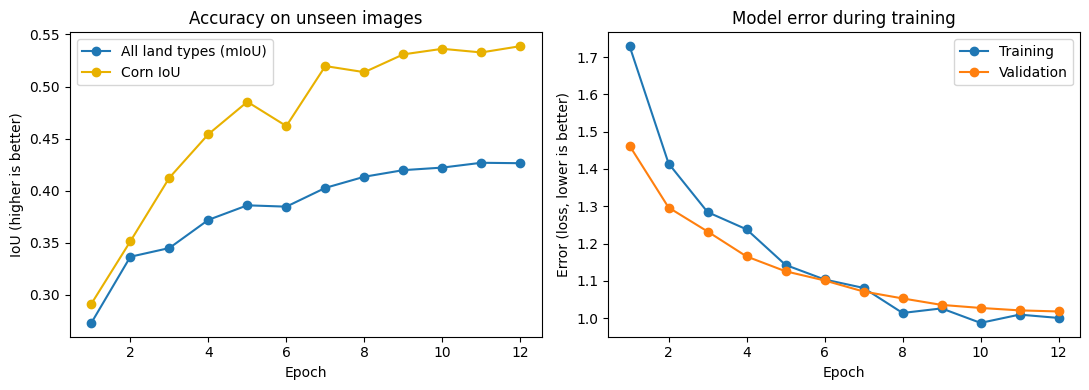

In [15]:
m = pd.read_csv(os.path.join(logger.log_dir, "metrics.csv"))
val = m.dropna(subset=["val/mIoU"]).groupby("epoch").last()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(val.index + 1, val["val/mIoU"], marker="o", label="All land types (mIoU)")
if "val/IoU_Corn" in val:
    ax[0].plot(val.index + 1, val["val/IoU_Corn"], marker="o", color="#e8b100", label="Corn IoU")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("IoU (higher is better)")
ax[0].set_title("Accuracy on unseen images"); ax[0].legend()

if "train/loss" in m:
    tr = m.dropna(subset=["train/loss"]).groupby("epoch")["train/loss"].mean()
    ax[1].plot(tr.index + 1, tr.values, marker="o", label="Training")
if "val/loss" in val:
    ax[1].plot(val.index + 1, val["val/loss"], marker="o", label="Validation")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Error (loss, lower is better)")
ax[1].set_title("Model error during training"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, "learning_curve.png"), dpi=150); plt.show()

## Step 9 — Final scores
For comparison: our first test run scored **0.357** corn IoU. IBM's published fine-tuned model ([Prithvi-EO-1.0-100M](https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-1.0-100M-multi-temporal-crop-classification), a 100M-parameter backbone trained for 80 epochs) reports **0.549** corn IoU and **0.427** mIoU on the same dataset. Our model has a ~5M-parameter backbone (9.8M parameters including our decoder) and trained for 12 epochs.

INFO: Restoring states from the checkpoint path at /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃               Test metric                ┃               DataLoader 0               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│              test/Accuracy               │            0.6512259840965271            │
│            test/Boundary_mIoU            │           0.31345927715301514            │
│       test/Class_Accuracy_Alfalfa        │            0.7118374109268188            │
│         test/Class_Accuracy_Corn         │            0.6245720386505127            │
│        test/Class_Accuracy_Cotton        │            0.7609769701957703            │
│   test/Class_Accuracy_Developed_Barren   │            0.4920663833618164            │
│ test/Class_Accuracy_Fallow_Idle_Cropland │            0.6219092011451721            │
│        test/Class_Accuracy_Forest        │            0.6218745112419128            │
│  test/Class_Accuracy_Natural_Vegetation  │           0.45986324548721313            │
│      test/Class_Accuracy_Open_Water      │            0.8962906002998352            │
│        test/Class_Accuracy_Other         │            0.5256334543228149            │
│       test/Class_Accuracy_Sorghum        │            0.7385654449462891            │
│       test/Class_Accuracy_Soybeans       │            0.6898918151855469            │
│       test/Class_Accuracy_Wetlands       │            0.624288022518158             │
│     test/Class_Accuracy_Winter_Wheat     │            0.6981687545776367            │
│              test/F1_Score               │            0.5927906632423401            │
│             test/IoU_Alfalfa             │            0.3058023452758789            │
│              test/IoU_Corn               │            0.532696008682251             │
│             test/IoU_Cotton              │           0.36489900946617126            │
│        test/IoU_Developed_Barren         │           0.33171626925468445            │
│      test/IoU_Fallow_Idle_Cropland       │           0.36229047179222107            │
│             test/IoU_Forest              │           0.45147839188575745            │
│       test/IoU_Natural_Vegetation        │            0.3979116976261139            │
│           test/IoU_Open_Water            │            0.6160886287689209            │
│              test/IoU_Other              │           0.36791524291038513            │
│             test/IoU_Sorghum             │           0.35576942563056946            │
│            test/IoU_Soybeans             │            0.526109516620636             │
│            test/IoU_Wetlands             │            0.4200495481491089            │
│          test/IoU_Winter_Wheat           │            0.5155967473983765            │
│           test/Pixel_Accuracy            │            0.6034855842590332            │
│                test/loss                 │            1.020706295967102             │
│                test/mIoU                 │            0.4267941117286682            │
│             test/mIoU_Micro              │           0.43213698267936707            │
└──────────────────────────────────────────┴──────────────────────────────────────────┘


===== RESULTS =====
test/mIoU                 0.427
test/Pixel_Accuracy       0.603
test/IoU_Corn             0.533
test/IoU_Soybeans         0.526


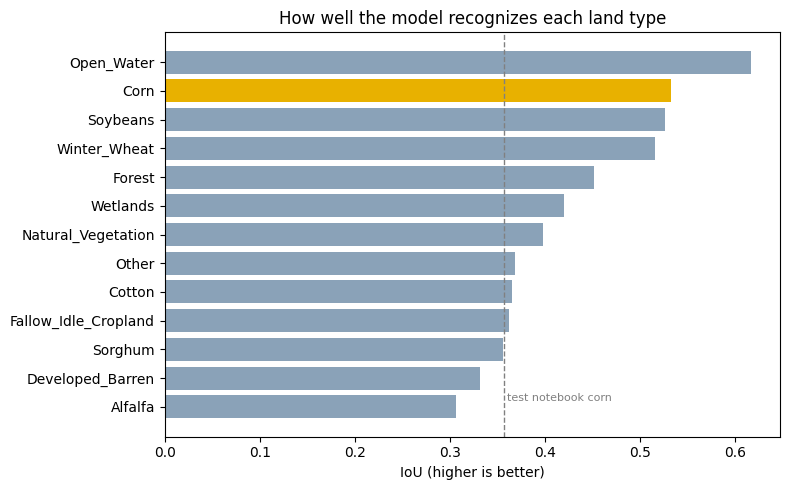

In [16]:
ckpt_path = checkpoint_callback.best_model_path or None
results = trainer.test(model, datamodule=data_module, ckpt_path=ckpt_path)[0]

print("\n===== RESULTS =====")
for k in ["test/mIoU", "test/Pixel_Accuracy", "test/IoU_Corn", "test/IoU_Soybeans"]:
    if k in results:
        print(f"{k:25s} {results[k]:.3f}")

iou = {k.replace("test/IoU_", ""): v for k, v in results.items() if k.startswith("test/IoU_")}
names, vals = zip(*sorted(iou.items(), key=lambda kv: kv[1]))
plt.figure(figsize=(8, 5))
plt.barh(names, vals, color=["#e8b100" if n == "Corn" else "#8aa2b8" for n in names])
plt.axvline(0.357, color="gray", ls="--", lw=1); plt.text(0.36, 0.2, "test notebook corn", fontsize=8, color="gray")
plt.xlabel("IoU (higher is better)"); plt.title("How well the model recognizes each land type")
plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, "iou_by_class.png"), dpi=150); plt.show()

pd.Series({**results, "backbone": BACKBONE, "epochs": EPOCHS, "train_minutes": round(TRAIN_MIN, 1)}) \
  .to_csv(os.path.join(SAVE_DIR, "test_scores.csv"))

## Step 10 — Score every validation image and save `chip_results.csv`
For each of the 771 chips we record where it is, when it was photographed, how much of it is corn (predicted vs. actual), and how healthy the corn looks on each date (NDVI). Everything in Notebook 2 builds on this table.

In [17]:
def unwrap(p):
    """Predictions come back nested as ((prediction, label), filenames). Dig out the prediction tensor."""
    while isinstance(p, (tuple, list)):
        p = p[0]
    return p

preds = trainer.predict(model, datamodule=data_module, ckpt_path=ckpt_path)
pred_masks = torch.cat([unwrap(p).cpu() for p in preds])          # one predicted crop map per chip, in dataset order
ds = data_module.predict_dataset
meta = pd.read_csv(os.path.join(DATA_ROOT, "chips_df.csv")).set_index("chip_id")
R, NIR = BANDS.index("RED"), BANDS.index("NIR_NARROW")

rows, i = [], 0
for batch in trainer.predict_dataloaders:                         # loop over the same images again to read the raw pixel values
    img, mask = batch["image"].float(), batch["mask"]
    ndvi = (img[:, NIR] - img[:, R]) / (img[:, NIR] + img[:, R] + 1e-6)   # NDVI = how green and healthy the vegetation is
    for b in range(img.shape[0]):
        chip_id = os.path.basename(ds.image_files[i]).replace("_merged.tif", "")
        pm, valid = pred_masks[i], mask[b] >= 0
        corn_pred, corn_true = (pm == CORN), (mask[b] == CORN)
        row = {
            "chip_id": chip_id,
            "lat": round(float(batch["location_coords"][b][0]), 5),
            "lon": round(float(batch["location_coords"][b][1]), 5),
            "tile": meta.loc[chip_id, "tile"],
            "date_1": meta.loc[chip_id, "first_img_date"][:10],
            "date_2": meta.loc[chip_id, "middle_img_date"][:10],
            "date_3": meta.loc[chip_id, "last_img_date"][:10],
            "corn_share_pred": round(corn_pred.float().mean().item(), 4),
            "corn_share_true": round((corn_true & valid).float().sum().item() / max(valid.sum().item(), 1), 4),
        }
        for t in range(NUM_FRAMES):
            row[f"corn_ndvi_{t+1}"] = round(ndvi[b, t][corn_pred].mean().item(), 4) if corn_pred.sum() > 50 else None
        rows.append(row)
        i += 1

chips = pd.DataFrame(rows)
chips.to_csv(os.path.join(SAVE_DIR, "chip_results.csv"), index=False)
print(f"Saved {len(chips)} chips to {SAVE_DIR}/chip_results.csv")
chips.head()

INFO: Restoring states from the checkpoint path at /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at /content/drive/MyDrive/cornsight/checkpoints/prithvi_eo_v2_tiny_tl-best-epoch=10.ckpt
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

Saved 771 chips to /content/drive/MyDrive/cornsight/chip_results.csv


,chip_id,lat,lon,tile,date_1,date_2,date_3,corn_share_pred,corn_share_true,corn_ndvi_1,corn_ndvi_2,corn_ndvi_3
0,chip_002_060,48.93247,-122.63362,10UEV,2022-03-06,2022-07-19,2022-09-27,0.0027,0.0085,0.4896,0.6361,0.5912
1,chip_009_061,48.53802,-122.37271,10UEU,2022-06-24,2022-07-29,2022-09-27,0.0034,0.0797,0.3176,0.6535,0.7314
2,chip_024_087,48.06813,-119.76947,10UGU,2022-06-26,2022-08-15,2022-09-24,0.0000,0.0002,NaN,NaN,NaN
3,chip_033_196,48.84395,-109.99480,12UWV,2022-07-19,2022-08-18,2022-09-27,0.0000,0.0000,NaN,NaN,NaN
4,chip_034_112,47.83447,-117.39101,11UMP,2022-06-23,2022-08-17,2022-09-26,0.0000,0.0000,NaN,NaN,NaN


## Step 11 — How well does the model measure corn?
1. **Acreage check:** predicted vs. actual corn share for each chip. The closer the dots sit to the diagonal, the better.
2. **Where the corn is:** every chip on a US map, coloured by predicted corn share. The Corn Belt should stand out.

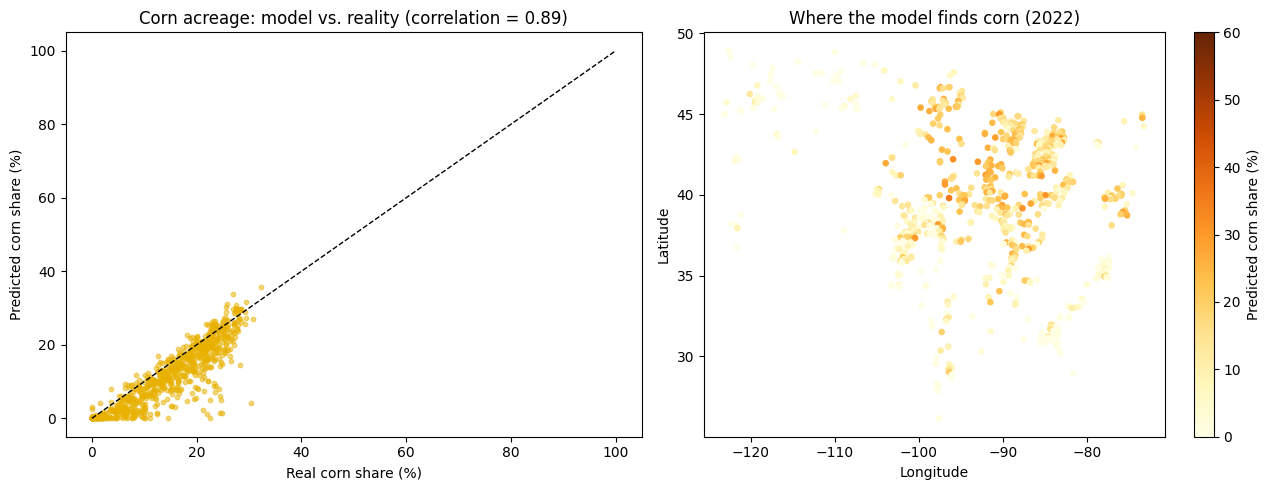

Correlation between predicted and real corn share: 0.89  (1.0 = perfect)


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(chips.corn_share_true * 100, chips.corn_share_pred * 100, s=10, alpha=0.5, color="#e8b100")
ax[0].plot([0, 100], [0, 100], "k--", lw=1)
r = chips[["corn_share_true", "corn_share_pred"]].corr().iloc[0, 1]
ax[0].set_xlabel("Real corn share (%)"); ax[0].set_ylabel("Predicted corn share (%)")
ax[0].set_title(f"Corn acreage: model vs. reality (correlation = {r:.2f})")

sc = ax[1].scatter(chips.lon, chips.lat, c=chips.corn_share_pred * 100, cmap="YlOrBr", s=14, vmin=0, vmax=60)
plt.colorbar(sc, ax=ax[1], label="Predicted corn share (%)")
ax[1].set_xlabel("Longitude"); ax[1].set_ylabel("Latitude"); ax[1].set_title("Where the model finds corn (2022)")
plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, "corn_acreage.png"), dpi=150); plt.show()
print(f"Correlation between predicted and real corn share: {r:.2f}  (1.0 = perfect)")

## Step 12 — Corn maps (the 4 chips with the most corn)
Left: what the satellite saw mid-season. Middle: the actual crop map. Right: our model's prediction. Corn is shown in gold.

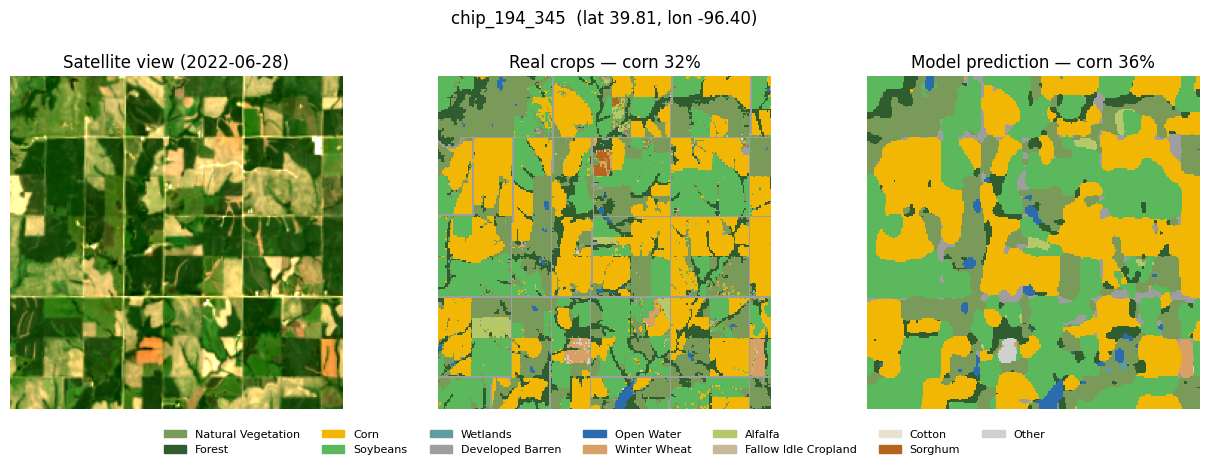

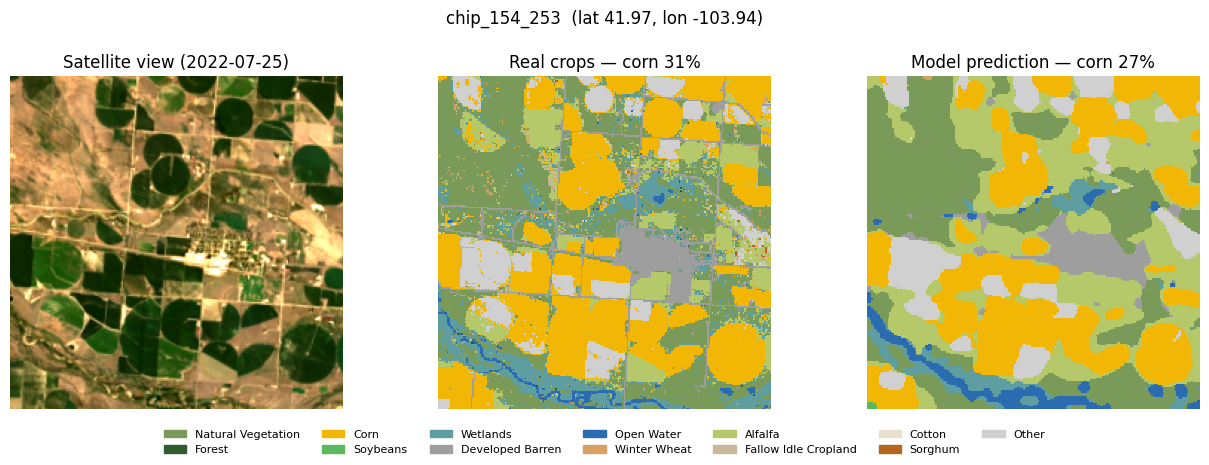

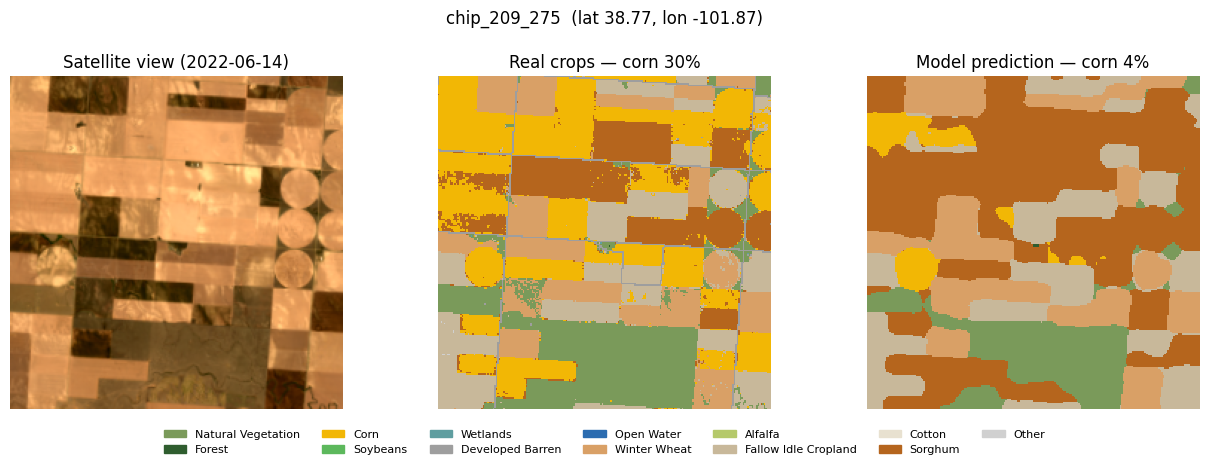

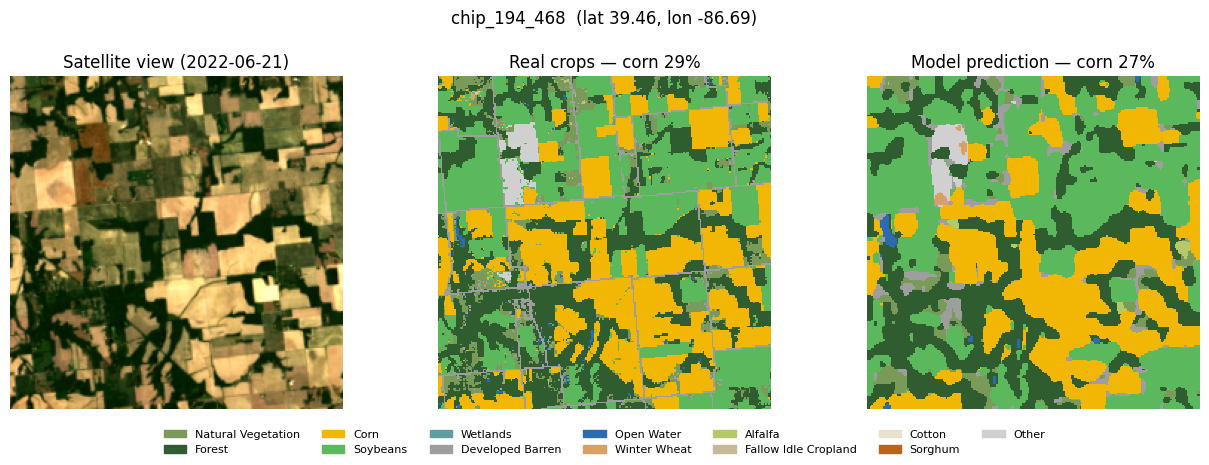

In [19]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Colours: corn = gold, soybeans = green, other crops = tan, nature = dark green, water = blue, built-up = gray
PALETTE = {"Natural_Vegetation": "#7a9a5a", "Forest": "#2f5d2f", "Corn": "#f2b705", "Soybeans": "#5cb85c",
           "Wetlands": "#5f9ea0", "Developed_Barren": "#9e9e9e", "Open_Water": "#2b6cb0", "Winter_Wheat": "#d9a066",
           "Alfalfa": "#b5c96a", "Fallow_Idle_Cropland": "#c8b89a", "Cotton": "#e8e1d0", "Sorghum": "#b5651d",
           "Other": "#d0d0d0"}
cmap = ListedColormap([PALETTE[c] for c in CLASS_NAMES])

def true_color(image, t=1):
    """Turn the raw satellite bands of photo t into a normal-looking color picture."""
    rgb = image[[BANDS.index("RED"), BANDS.index("GREEN"), BANDS.index("BLUE")], t].numpy().transpose(1, 2, 0)
    lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

top = chips.sort_values("corn_share_true", ascending=False).head(4).index
for idx in top:
    sample = ds[idx]
    true_mask = sample["mask"].numpy().astype(float)
    true_mask[true_mask < 0] = np.nan                      # leave unlabelled pixels blank
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
    ax[0].imshow(true_color(sample["image"])); ax[0].set_title(f"Satellite view ({chips.date_2[idx]})")
    ax[1].imshow(true_mask, cmap=cmap, vmin=0, vmax=len(CLASS_NAMES) - 1, interpolation="nearest")
    ax[1].set_title(f"Real crops — corn {chips.corn_share_true[idx]*100:.0f}%")
    ax[2].imshow(pred_masks[idx].numpy(), cmap=cmap, vmin=0, vmax=len(CLASS_NAMES) - 1, interpolation="nearest")
    ax[2].set_title(f"Model prediction — corn {chips.corn_share_pred[idx]*100:.0f}%")
    for a in ax: a.axis("off")
    fig.legend(handles=[Patch(color=PALETTE[c], label=c.replace("_", " ")) for c in CLASS_NAMES],
               loc="lower center", ncol=7, fontsize=8, frameon=False)
    fig.suptitle(f"{chips.chip_id[idx]}  (lat {chips.lat[idx]:.2f}, lon {chips.lon[idx]:.2f})")
    plt.tight_layout(rect=(0, 0.08, 1, 0.94))
    plt.savefig(os.path.join(SAVE_DIR, f"map_{chips.chip_id[idx]}.png"), dpi=150, bbox_inches="tight")
    plt.show()

## Summary
- The fine-tuned model reached **0.533 corn IoU** and **0.427 mIoU**, essentially matching IBM's published Prithvi-EO-1.0-100M (0.549 / 0.427) with a backbone about 20× smaller. Predicted vs. actual corn share per chip has a **0.89 correlation**, and the model finds **62.5%** of real corn pixels.
- **Caveats:** the USDA Cropland Data Layer labels are noisy, and the 771 validation chips were also used to pick the best checkpoint (epoch 10), so these scores may be slightly optimistic.
- The model checkpoint, scores, charts and `chip_results.csv` are saved to Drive, and the files Notebook 2 needs are also in our public GitHub repo (`AlonsoManchego/cornsight`).
- **Next:** Notebook 2 turns these results into market intelligence.